# Q-Learning with Gymnasium (PyTorch)

In the previous notebook we estimated $V(s)$ for a **fixed** policy. Now we want the agent to **find the best policy**.
To do that we learn action values instead:

$$Q(s, a) = \text{expected return after taking action } a \text{ in state } s \text{, then acting optimally}$$

If we know $Q$, the best policy is simply $\pi(s) = \arg\max_a Q(s, a)$.

### The Q-learning update
It is TD learning again. Same update shape, new target:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \Big(\underbrace{r + \gamma \max_{a'} Q(s', a')}_{\text{TD target}} - Q(s,a)\Big)$$

| | Target | Learns the value of... |
|---|---|---|
| TD(0) (last notebook) | $r + \gamma V(s')$ | the policy being followed |
| SARSA | $r + \gamma Q(s', a')$, with $a'$ the action actually taken next | the policy being followed (**on-policy**) |
| **Q-learning** | $r + \gamma \max_{a'} Q(s', a')$ | the **greedy** policy, whatever we actually do (**off-policy**) |

The $\max$ is the whole trick. The agent can **explore** (act randomly sometimes) while still learning the
value of acting **optimally**.

### Plan
1. **CliffWalking**: Q-learning vs SARSA, the classic example of off-policy vs on-policy (Sutton & Barto, Example 6.6).
2. **FrozenLake (slippery)**: the same agent on a stochastic environment, with decaying exploration.

!pip install gymnasium

In [2]:
# !pip install gymnasium torch matplotlib     # uncomment if needed
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch

print("gymnasium", gym.__version__, "| torch", torch.__version__)


def make_env(name, versions, **kw):
    '''Create the newest available version of an environment (names change between gymnasium releases).'''
    for v in versions:
        try:
            return gym.make(f"{name}-{v}", **kw)
        except (gym.error.Error, gym.error.DeprecatedEnv):
            continue
    raise RuntimeError(f"No version of {name} found")

gymnasium 1.4.0 | torch 2.14.1


## Environment 1: CliffWalking

```
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
S  C  C  C  C  C  C  C  C  C  C  G
```

- 48 states (a 4×12 grid) and 4 actions: 0 = up, 1 = right, 2 = down, 3 = left.
- Every step gives **−1**, so the agent wants the shortest path.
- Stepping into the **Cliff (C)** gives **−100** and teleports the agent back to S. The episode does not end.
- The optimal path walks right along the edge of the cliff: 13 steps, return −13.

In [3]:
env = make_env("CliffWalking", ["v1", "v0"], max_episode_steps=500)
n_states, n_actions = env.observation_space.n, env.action_space.n
print("states:", n_states, "| actions:", n_actions)

# the gymnasium API in four lines
s, info = env.reset(seed=0)
s_next, r, terminated, truncated, info = env.step(1)       # move right, straight into the cliff
print(f"state {s} --right--> state {s_next}, reward {r}, terminated={terminated}, truncated={truncated}")

states: 48 | actions: 4
state 36 --right--> state 36, reward -100, terminated=False, truncated=False


### Two details that matter in every Gymnasium agent

**1. `terminated` vs `truncated`.** `terminated` means the episode really ended (goal reached, fell in a hole),
so the future is worth 0. `truncated` means a time limit cut the episode short. The state still has a future,
so we **should** bootstrap from it. That is why the target uses `(1 - terminated)` and not `(1 - done)`.

**2. Exploration with ε-greedy.** With probability ε take a random action, otherwise the best one.
We break ties randomly. Otherwise, at the start, when every Q value is 0, `argmax` would always pick action 0.

In [4]:
def epsilon_greedy(Q, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(Q.shape[1]))
    q = Q[s]
    best = torch.nonzero(q == q.max()).flatten()            # all actions tied for best
    return int(best[rng.integers(len(best))])

## The agents

Both functions share the same loop. The **only** difference is the TD target, which is marked below.
`eps` can be a number or a function of the episode index, for decaying exploration later on.

In [5]:
def q_learning(env, episodes, alpha=0.5, gamma=1.0, eps=0.1, seed=0):
    rng = np.random.default_rng(seed)
    Q = torch.zeros(env.observation_space.n, env.action_space.n)
    returns = []
    s, _ = env.reset(seed=seed)
    for ep in range(episodes):
        if ep > 0:
            s, _ = env.reset()
        e = eps(ep) if callable(eps) else eps
        G, done = 0.0, False
        while not done:
            a = epsilon_greedy(Q, s, e, rng)                      # behave: explore
            s2, r, terminated, truncated, _ = env.step(a)
            target = r + gamma * Q[s2].max() * (1 - terminated)   # <-- learn: assume GREEDY next action
            Q[s, a] += alpha * (target - Q[s, a])
            s, G, done = s2, G + r, terminated or truncated
        returns.append(G)
    return Q, np.array(returns)


def sarsa(env, episodes, alpha=0.5, gamma=1.0, eps=0.1, seed=0):
    rng = np.random.default_rng(seed)
    Q = torch.zeros(env.observation_space.n, env.action_space.n)
    returns = []
    s, _ = env.reset(seed=seed)
    for ep in range(episodes):
        if ep > 0:
            s, _ = env.reset()
        e = eps(ep) if callable(eps) else eps
        a = epsilon_greedy(Q, s, e, rng)
        G, done = 0.0, False
        while not done:
            s2, r, terminated, truncated, _ = env.step(a)
            a2 = epsilon_greedy(Q, s2, e, rng)                    # the action we WILL take
            target = r + gamma * Q[s2, a2] * (1 - terminated)     # <-- learn: use the ACTUAL next action
            Q[s, a] += alpha * (target - Q[s, a])
            s, a, G, done = s2, a2, G + r, terminated or truncated
        returns.append(G)
    return Q, np.array(returns)

## Experiment 1: Q-learning vs SARSA on CliffWalking

Both agents use a fixed ε = 0.1 and α = 0.5. We record the return of every training episode,
averaged over 20 independent runs.

Q-learning  avg return during the last 100 episodes: -49.6
SARSA       avg return during the last 100 episodes: -29.9


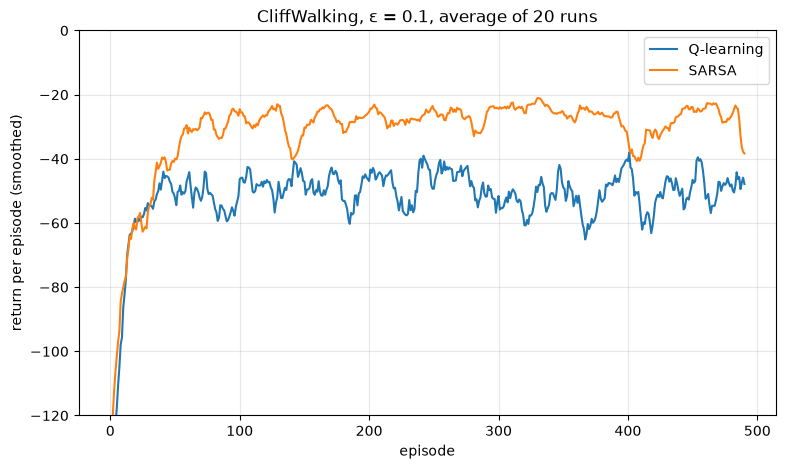

In [6]:
EPISODES, RUNS = 500, 20
curves, tables = {}, {}
for name, agent in [("Q-learning", q_learning), ("SARSA", sarsa)]:
    results = [agent(env, EPISODES, seed=run) for run in range(RUNS)]
    curves[name] = np.mean([ret for _, ret in results], axis=0)
    tables[name] = results[0][0]                     # keep one Q-table for plotting
    print(f"{name:<11} avg return during the last 100 episodes: {curves[name][-100:].mean():.1f}")


def smooth(x, k=10):
    return np.convolve(x, np.ones(k) / k, mode="valid")

plt.figure(figsize=(9, 5))
for name, c in curves.items():
    plt.plot(smooth(c), label=name)
plt.ylim(-120, 0); plt.xlabel("episode"); plt.ylabel("return per episode (smoothed)")
plt.title(f"CliffWalking, ε = 0.1, average of {RUNS} runs"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Surprise: SARSA collects *more* reward during training**, even though Q-learning learns the *optimal* path.
To see why, look at the policies each one learned.

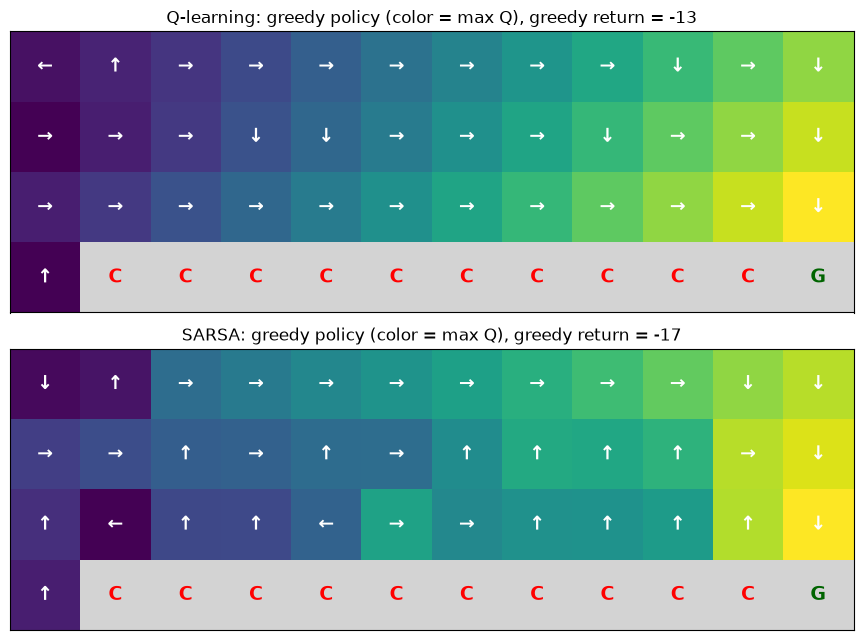

In [7]:
CLIFF_ARROWS = "↑→↓←"                      # CliffWalking actions: 0 up, 1 right, 2 down, 3 left

def plot_cliff_policy(Q, ax, title):
    V = Q.max(1).values.reshape(4, 12).numpy().copy()
    V[3, 1:] = np.nan                                    # cliff + goal: not real decision states
    cmap = plt.get_cmap("viridis").copy(); cmap.set_bad("lightgray")
    ax.imshow(np.ma.masked_invalid(V), cmap=cmap)
    for s in range(48):
        r, c = divmod(s, 12)
        if r == 3 and 0 < c < 11:
            label, color = "C", "red"
        elif s == 47:
            label, color = "G", "darkgreen"
        else:
            label, color = CLIFF_ARROWS[int(Q[s].argmax())], "white"
        ax.text(c, r, label, ha="center", va="center", color=color, fontsize=14, fontweight="bold")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])


def greedy_path(env, Q, max_steps=100):
    '''Follow argmax Q from the start and return the visited states and the total reward.'''
    s, _ = env.reset()
    path, G = [s], 0.0
    for _ in range(max_steps):
        s, r, terminated, truncated, _ = env.step(int(Q[s].argmax()))
        path.append(s); G += r
        if terminated or truncated:
            break
    return path, G


fig, axes = plt.subplots(2, 1, figsize=(10, 6.5))
for ax, (name, Q) in zip(axes, tables.items()):
    path, G = greedy_path(env, Q)
    plot_cliff_policy(Q, ax, f"{name}: greedy policy (color = max Q), greedy return = {G:.0f}")
plt.tight_layout(); plt.show()

**What happened**

- **Q-learning** learns the value of the *greedy* policy, so its arrows trace the optimal path right along the
  cliff edge (return −13). But during training it still explores with ε = 0.1. When it walks the edge,
  a random step sometimes drops it into the cliff (−100). That is why its training returns are worse.
- **SARSA** learns the value of the policy it *actually follows*, including the random steps. Walking next to the
  cliff is genuinely dangerous for an ε-greedy agent, so SARSA learns a **safer path further from the edge**.

This is the core idea of **off-policy** learning: Q-learning's behavior policy (ε-greedy) differs from the
policy it learns about (greedy). If ε is decayed to 0, both converge to the optimal path.

## Environment 2: FrozenLake (slippery)

```
S F F F        S = start, F = frozen (safe), H = hole (episode ends, reward 0)
F H F H        G = goal (reward +1)
F F F H
H F F G
```

The ice is **slippery**: the agent moves in the intended direction only 1/3 of the time, otherwise sideways.
The only reward is +1 at the goal, so it is **sparse**. Two changes compared with CliffWalking:

- **γ = 0.99.** With γ = 1 every successful path is worth exactly 1, so the agent has no reason to hurry.
- **Decaying ε.** Explore a lot at first, when the agent knows nothing, and exploit more later.
  The smaller α = 0.1 averages out the random outcomes of the slippery moves.

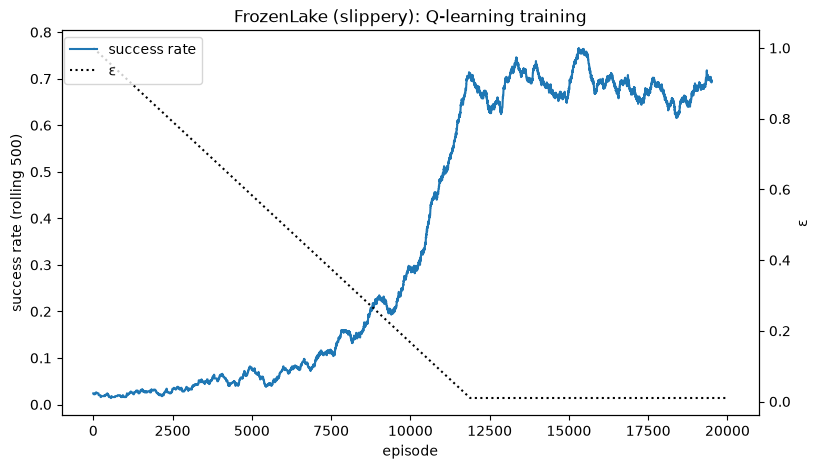

In [8]:
lake = make_env("FrozenLake", ["v1"], is_slippery=True)
EPISODES_FL = 20_000
eps_schedule = lambda ep: max(0.01, 1.0 - ep / (0.6 * EPISODES_FL))      # linear decay 1.0 -> 0.01

Q_lake, ret_lake = q_learning(lake, EPISODES_FL, alpha=0.1, gamma=0.99, eps=eps_schedule, seed=0)

window = 500
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(np.convolve(ret_lake, np.ones(window) / window, mode="valid"), label="success rate")
ax1.set_xlabel("episode"); ax1.set_ylabel(f"success rate (rolling {window})")
ax2 = ax1.twinx()
ax2.plot([eps_schedule(e) for e in range(EPISODES_FL)], "k:", label="ε")
ax2.set_ylabel("ε")
ax1.set_title("FrozenLake (slippery): Q-learning training")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88)); plt.show()

### Evaluating the learned policy

Training returns are measured *while exploring*. To judge the policy itself, run it greedily (ε = 0) many times.
As a baseline we also evaluate the greedy policy of a *random* Q-table, which almost never reaches the goal. The best possible policy on the slippery 4×4 map succeeds about 74% of the time, because some falls are unavoidable.

In [9]:
def evaluate(env, Q, episodes=2000, seed=123):
    wins = 0
    s, _ = env.reset(seed=seed)
    for ep in range(episodes):
        if ep > 0:
            s, _ = env.reset()
        done = False
        while not done:
            s, r, terminated, truncated, _ = env.step(int(Q[s].argmax()))
            done = terminated or truncated
        wins += r
    return wins / episodes

print(f"random Q-table: {evaluate(lake, torch.rand(16, 4, generator=torch.Generator().manual_seed(0))):.1%}")
print(f"learned policy: {evaluate(lake, Q_lake):.1%}")

random Q-table: 0.0%
learned policy: 75.6%


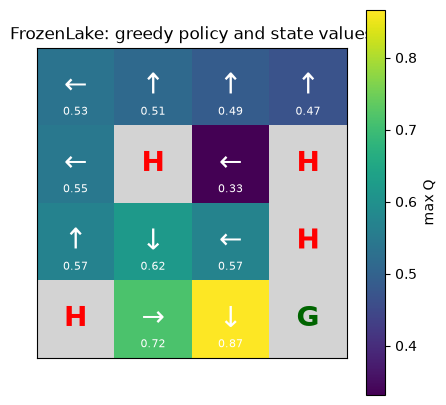

In [10]:
LAKE_ARROWS = "←↓→↑"                       # FrozenLake actions: 0 left, 1 down, 2 right, 3 up
desc = lake.unwrapped.desc.astype(str)

V = Q_lake.max(1).values.reshape(4, 4).numpy()
V_plot = np.where(np.isin(desc, ["H", "G"]), np.nan, V)          # grey out terminal tiles
cmap = plt.get_cmap("viridis").copy(); cmap.set_bad("lightgray")
plt.figure(figsize=(5, 5))
plt.imshow(np.ma.masked_invalid(V_plot), cmap=cmap)
for s in range(16):
    r, c = divmod(s, 4)
    tile = desc[r, c]
    if tile in "HG":
        plt.text(c, r, tile, ha="center", va="center", color="red" if tile == "H" else "darkgreen",
                 fontsize=20, fontweight="bold")
    else:
        plt.text(c, r, LAKE_ARROWS[int(Q_lake[s].argmax())], ha="center", va="center",
                 color="white", fontsize=20)
        plt.text(c, r + 0.33, f"{V[r, c]:.2f}", ha="center", va="center", color="white", fontsize=8)
plt.colorbar(label="max Q"); plt.xticks([]); plt.yticks([])
plt.title("FrozenLake: greedy policy and state values"); plt.show()

**Reading the policy:** some arrows look strange. Next to a hole, the agent often points *away* from where it
wants to go. Because the ice slips sideways, "push against the wall" is the move that can never slide you
into the hole. Q-learning discovered this purely from experience, without being given any model of the ice.

## Summary

- Q-learning is TD learning on $Q(s,a)$ with the target $r + \gamma \max_{a'} Q(s',a')$.
- The $\max$ makes it **off-policy**: it explores with ε-greedy but learns the value of the greedy policy.
  That gives the optimal policy, though the agent may train "dangerously" (CliffWalking).
- Practical details: bootstrap on `truncated` but not on `terminated`, break argmax ties randomly, decay ε,
  and evaluate greedily, separately from training.

**Things to try**
- Set ε → 0 over time on CliffWalking and watch SARSA's path move toward the edge.
- Use `FrozenLake-v1` with `map_name="8x8"` (needs many more episodes) or `is_slippery=False`.
- Try `Taxi` (500 states, 6 actions) with the very same `q_learning` function.
- **Next step: DQN.** Replace the table with a neural network `Q_θ(s)`, then add a replay buffer and a target network.
  It is the same semi-gradient idea as the value network in the previous notebook.